# Linear Regression with Real Data

ECON526

Paul Schrimpf (University of British Columbia)

## AI Usage

These slides were entirely generated by Deepseek V4.1 Flash. See
regression_realdata_v1 for the original version. For these, I had GLM
5.3 Flash critique the original slides and then Deepseek V4.1 Flash
revise them. They are better, but still not very good.

# Real-Data Examples

## Why Replace the Synthetic Examples?

- The synthetic examples in [regression.qmd](regression.qmd) were
  constructed by design and sized for illustration. This deck re-runs
  the same lessons on published datasets that can be traced and cited.
- This deck uses four published replication datasets to illustrate:
  1.  bad controls, mediators, and colliders;
  2.  stratified randomization when treatment probabilities and
      treatment effects vary;
  3.  why stratified/saturated regression can reduce standard errors in
      an RCT;
  4.  a real-data sign reversal from omitted scale/population.
- Standard errors are HC3 unless observations are clustered: we cluster
  by ethnic group in the Nunn–Wantchekon data and by school in STAR.
- The examples are deliberately chosen so that the data and the original
  paper can be traced and cited.

## The Four Datasets

| Dataset | Paper | Main use here |
|------------------------|------------------------|------------------------|
| Afrobarometer + slave exports | Nunn and Wantchekon (2011b) | bad control / mediator |
| Oregon Health Insurance Experiment | Finkelstein et al. (2012) | treatment probabilities, weighting, and effect heterogeneity |
| Project STAR | Krueger (1999); Achilles et al. (2008) | stratified regression and SEs |
| German city associations | Satyanath et al. (2017a) | sign reversal from omitted scale |

## Data Sources and Redistribution

| Dataset | Source | Redistribute in this repo? |
|------------------------|------------------------|------------------------|
| Nunn–Wantchekon | AEA/openICPSR, [doi:10.3886/E112479V1](https://doi.org/10.3886/E112479V1); public mirror used by the code | **No.** The raw `.dta` is not committed. The code downloads it from a public course mirror; the original replication package is the citation above. |
| OHIE | Harvard Dataverse, [doi:10.7910/DVN/SJG1ED](https://doi.org/10.7910/DVN/SJG1ED) | **Yes**, for the small processed extract. Original is CC0 with additional terms: no commercial use, no re-identification, and cite the data. |
| Project STAR | Harvard Dataverse, [doi:10.7910/DVN/SIWH9F](https://doi.org/10.7910/DVN/SIWH9F) | **Yes.** CC0; a processed extract is included. |
| Bowling for Fascism | Harvard Dataverse, [doi:10.7910/DVN/EE6I7N](https://doi.org/10.7910/DVN/EE6I7N) | **Yes.** CC0; a processed extract is included. |

The Nunn–Wantchekon raw file is not redistributed here. If the download
fails, obtain `Nunn_Wantchekon_AER_2011.dta` from the AEA/openICPSR
package or from the public IQSS mirror linked in the code below.

# Bad Controls, Mediators, and Colliders

## Nunn and Wantchekon (2011)

- Question: did the transatlantic and Indian Ocean slave trades leave a
  legacy of mistrust in Africa?
- Treatment: `ln_export_area`, log slave exports per historical
  ethnic-group area.
- Outcome: trust in the local government council.
- Candidate control: perceived performance/quality of the local council.

In [1]:
import os
import numpy as np
import pandas as pd
import requests
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

nunn_path = "data/replication/Nunn_Wantchekon_AER_2011.dta"
nunn_url = ("https://raw.githubusercontent.com/iqss/prefresher/"
            "4e97fcafa50093a46a24c5aa5134562190740d40/"
            "data/input/Nunn_Wantchekon_AER_2011.dta")
if not os.path.exists(nunn_path):
    r = requests.get(nunn_url, timeout=60)
    r.raise_for_status()
    with open(nunn_path, "wb") as f:
        f.write(r.content)

nunn = pd.read_stata(nunn_path)
assert nunn.shape[0] > 20_000, "unexpected Nunn-Wantchekon extract"
for c in ["isocode", "occupation", "religion", "living_conditions", "education"]:
    nunn[c] = nunn[c].astype("category")

nunn_vars = [
    "trust_local_council", "ln_export_area", "age", "age2", "male", "urban_dum",
    "occupation", "religion", "living_conditions", "education",
    "isocode", "district", "ethnicity",
    "local_council_performance", "council_listen", "corrupt_local_council",
]
nunn_d = nunn.dropna(subset=nunn_vars).copy()

## Nunn and Wantchekon (2011)

- What happens when we add local-council quality?
- If council quality is a **mediator**, the coefficient is no longer the
  total effect.
- If council quality is a **collider**, conditioning opens a non-causal
  path; see Schneider (2020) for this concern in economic history.

In [2]:
nunn_models = {
    "(1) bivariate": "trust_local_council ~ ln_export_area",
    "(2) + individual controls": (
        "trust_local_council ~ ln_export_area + age + age2 + male + urban_dum "
        "+ C(occupation) + C(religion) + C(living_conditions) + C(education)"
    ),
    "(3) + country FE": (
        "trust_local_council ~ ln_export_area + age + age2 + male + urban_dum "
        "+ C(occupation) + C(religion) + C(living_conditions) + C(education) "
        "+ C(isocode)"
    ),
    "(4) + council performance": (
        "trust_local_council ~ ln_export_area + age + age2 + male + urban_dum "
        "+ C(occupation) + C(religion) + C(living_conditions) + C(education) "
        "+ C(isocode) + local_council_performance"
    ),
    "(5) + all council quality": (
        "trust_local_council ~ ln_export_area + age + age2 + male + urban_dum "
        "+ C(occupation) + C(religion) + C(living_conditions) + C(education) "
        "+ C(isocode) + local_council_performance + council_listen "
        "+ corrupt_local_council"
    ),
}
nunn_rows = []
for name, form in nunn_models.items():
    m = smf.ols(form, data=nunn_d).fit(
        cov_type="cluster", cov_kwds={"groups": nunn_d["ethnicity"]}
    )
    nunn_rows.append({
        "Specification": name,
        "Coefficient on ln(exports)": m.params["ln_export_area"],
        "SE": m.bse["ln_export_area"],
        "N": int(m.nobs),
    })
nunn_table = pd.DataFrame(nunn_rows).set_index("Specification")
print(nunn_table.round(3).to_markdown())

| Specification             |   Coefficient on ln(exports) |    SE |     N |
|:--------------------------|-----------------------------:|------:|------:|
| (1) bivariate             |                       -0.152 | 0.061 | 15748 |
| (2) + individual controls |                       -0.131 | 0.044 | 15748 |
| (3) + country FE          |                       -0.113 | 0.02  | 15748 |
| (4) + council performance |                       -0.077 | 0.016 | 15748 |
| (5) + all council quality |                       -0.059 | 0.015 | 15748 |

## Nunn and Wantchekon (2011): Interpretation

- The coefficient declines monotonically:
  $-0.152 \to -0.131 \to -0.113 \to -0.077 \to -0.059$.
- Columns (1)–(3) add individual controls and country fixed effects.
  Columns (4)–(5) add the council-quality measures.
- The total effect of the slave trade includes any effect operating
  through local institutions. Holding council quality fixed changes the
  estimand from a total effect to a direct effect, and it can also open
  a collider path if unobserved local public goods affect both council
  quality and trust.
- The decline is consistent with mediation, but it is also consistent
  with omitted variables. Distinguishing the two requires more than
  coefficient stability; Nunn and Wantchekon (2011b) use instrumental
  variables and additional outcomes.
- All columns use a common sample (N = 15,748). The unrestricted
  bivariate estimate is $-0.144$ (SE 0.062, N = 20,210). We cluster by
  ethnic group because slave-export exposure varies at that level.
- This is the real-data version of the “bad control” warning: more
  controls are not always better.

# Stratified Randomization and Treatment Effects

## Oregon Health Insurance Experiment

- Lottery-based Medicaid expansion in Oregon.
- Treatment: selected in the lottery.
- Outcome: any doctor visit in the in-person survey.
- Randomization was not i.i.d. across household sizes: lottery odds
  varied with the number of eligible household members.

In [3]:
ohie = pd.read_csv("data/replication/ohie_analysis.csv")
ohie = ohie.dropna(subset=["doc_any", "treatment", "numhh", "weight"]).copy()
ohie["numhh"] = ohie["numhh"].astype(int)

prob_table = (
    ohie.groupby("numhh")
    .agg(P_treated=("treatment", "mean"), N=("treatment", "size"))
    .reset_index()
)
print(prob_table.round(3).to_markdown(index=False))

ohie_effects = []
for h in sorted(ohie["numhh"].unique()):
    g = ohie[ohie["numhh"] == h]
    m = smf.wls("doc_any ~ treatment", data=g, weights=g["weight"]).fit(cov_type="HC3")
    ci = m.conf_int().loc["treatment"]
    ohie_effects.append({
        "Household size": h,
        "Effect on P(doctor visit)": m.params["treatment"],
        "SE": m.bse["treatment"],
        "CI low": ci.iloc[0],
        "CI high": ci.iloc[1],
        "N": int(m.nobs),
    })
print("\n" + pd.DataFrame(ohie_effects).round(3).to_markdown(index=False))

|   numhh |   P_treated |    N |
|--------:|------------:|-----:|
|       1 |       0.493 | 9235 |
|       2 |       0.613 | 2952 |
|       3 |       0.889 |   18 |

|   Household size |   Effect on P(doctor visit) |    SE |   CI low |   CI high |    N |
|-----------------:|----------------------------:|------:|---------:|----------:|-----:|
|                1 |                       0.036 | 0.011 |    0.016 |     0.057 | 9235 |
|                2 |                       0.051 | 0.021 |    0.009 |     0.093 | 2952 |
|                3 |                       0.161 | 0.721 |   -1.251 |     1.573 |   18 |

## Oregon Health Insurance Experiment

- Simple difference versus adjustment for household size.
- All estimates use the in-person survey weights and are **ITT** effects
  of lottery selection, not effects of Medicaid: take-up is about 43%
  among selected households and 19% among non-selected households.

In [4]:
ohie_models = {
    "Simple difference": "doc_any ~ treatment",
    "+ household size": "doc_any ~ treatment + C(numhh)",
}
ohie_rows = []
for name, form in ohie_models.items():
    m = smf.wls(form, data=ohie, weights=ohie["weight"]).fit(cov_type="HC3")
    ohie_rows.append({
        "Specification": name,
        "Effect": m.params["treatment"],
        "SE": m.bse["treatment"],
        "N": int(m.nobs),
    })
print(pd.DataFrame(ohie_rows).set_index("Specification").round(4).to_markdown())

| Specification     |   Effect |     SE |     N |
|:------------------|---------:|-------:|------:|
| Simple difference |   0.0352 | 0.0095 | 12205 |
| + household size  |   0.04   | 0.0096 | 12205 |

## Oregon Health Insurance Experiment: What Is the Lesson?

- $P(D=1\mid X)$ varies with household size: about 0.49, 0.61, and 0.89
  in the analysis sample for one-, two-, and three-person households.
- The 1- and 2-person effects are similar in magnitude (about 3.6 and
  5.1 percentage points, with wide confidence intervals); the 3+
  estimate rests on only 18 observations and is too imprecise to
  interpret.
- Both the unadjusted and adjusted estimates are consistent in this
  stratified RCT; they differ because they weight stratum-specific
  effects differently.
- The unadjusted estimate is closer to a variance-weighted average of
  stratum effects: $$
  \hat\tau_{\text{unadj}} = \sum_h v_h \hat\tau_h, \qquad
  v_h = \frac{P(X=h)\,\mathrm{Var}(D\mid X=h)}{\sum_{h'} P(X=h')\,\mathrm{Var}(D\mid X=h')}.
  $$
- Adjusting for household size changes the estimand and the weights, not
  the validity of the experiment.
- In an observational study, the same uneven $P(D\mid X)$ combined with
  selection on $X$ would also bias the unadjusted estimate.
  Randomization is what rules out that bias here.
- Here `numhh` is a **good** control: it is pre-treatment and determines
  treatment probabilities. It is not a mediator.
- The in-person survey is a subsample; `doc_any` is missing for only
  about 0.2% of respondents after restricting to survey respondents.

# Stratified Regression and Standard Errors

## Project STAR

- Tennessee class-size experiment: students were randomized to small
  classes, regular classes, or regular classes with a teacher’s aide.
- Outcome: kindergarten reading score.
- Treatment: small class versus regular class (aide classes omitted for
  this comparison).
- School is a randomization stratum; baseline covariates are available.

In [5]:
star = pd.read_csv("data/replication/star_k.csv")
star = star[star["classtype"].isin([1, 2])].copy()
star["small"] = (star["classtype"] == 1).astype(int)
star = star.dropna(subset=["read", "small", "school", "gender", "race", "freelunch"])

star_models = {
    "Simple difference": "read ~ small",
    "+ school FE": "read ~ small + C(school)",
    "+ school FE + covariates": "read ~ small + C(school) + C(gender) + C(race) + C(freelunch)",
}
star_rows = []
for name, form in star_models.items():
    m = smf.ols(form, data=star).fit(
        cov_type="cluster", cov_kwds={"groups": star["school"]}
    )
    star_rows.append({
        "Specification": name,
        "Effect of small class": m.params["small"],
        "SE": m.bse["small"],
        "N": int(m.nobs),
    })
print(pd.DataFrame(star_rows).set_index("Specification").round(3).to_markdown())

| Specification            |   Effect of small class |    SE |    N |
|:-------------------------|------------------------:|------:|-----:|
| Simple difference        |                   5.899 | 1.851 | 3733 |
| + school FE              |                   6.702 | 1.784 | 3733 |
| + school FE + covariates |                   6.649 | 1.717 | 3733 |

## Project STAR: Interpretation

- The point estimate is stable at roughly 6–7 points.
- Controlling for the randomization stratum (school) and baseline
  covariates reduces the clustered standard error by about 7 percent.
- That is the intuition behind saturated/stratified regression in an
  RCT: removing predictable between-stratum variation in outcomes
  sharpens the treatment contrast.
- STAR randomizes students and teachers within schools, so we cluster by
  school. With many strata, fully interacting treatment with every
  stratum can be noisy; additive stratum effects are often the practical
  compromise.

# A Real Sign Reversal

## Bowling for Fascism

- Satyanath et al. (2017a) study 229 German towns and cities in the
  1920s.
- Treatment: association density (clubs per capita).
- The paper’s outcome is the **per-capita standardized** Nazi Party
  entry rate, `pcNSentry_std`.
- Association density is not randomized, so these are conditional
  associations, not causal effects.
- On the paper’s own outcome, the association is positive and stable:

In [6]:
bowling = pd.read_csv("data/replication/bowling_cities.csv")

paper_models = {
    "Bivariate": "pcNSentry_std ~ clubs_all_pc",
    "+ log population": "pcNSentry_std ~ clubs_all_pc + lnpop",
    "+ population controls": (
        "pcNSentry_std ~ clubs_all_pc + lnpop + share_cath25 "
        "+ bcollar25 + share_jew25"
    ),
}
paper_rows = []
for name, form in paper_models.items():
    m = smf.ols(form, data=bowling).fit(cov_type="HC3")
    paper_rows.append({
        "Specification": name,
        "Effect": m.params["clubs_all_pc"],
        "SE": m.bse["clubs_all_pc"],
        "N": int(m.nobs),
    })
print(pd.DataFrame(paper_rows).set_index("Specification").round(3).to_markdown())

| Specification         |   Effect |    SE |   N |
|:----------------------|---------:|------:|----:|
| Bivariate             |    0.126 | 0.052 | 229 |
| + log population      |    0.197 | 0.061 | 229 |
| + population controls |    0.162 | 0.055 | 227 |

## A Sign Reversal from Mismatching Units

- Now replace the per-capita outcome with the **total** number of Nazi
  entries, `NSentry_total`.
- The treatment is still clubs **per capita**. This mismatch produces a
  sign reversal:

In [7]:
count_models = {
    "Bivariate": "NSentry_total ~ clubs_all_pc",
    "+ log population": "NSentry_total ~ clubs_all_pc + lnpop",
    "+ population controls": (
        "NSentry_total ~ clubs_all_pc + lnpop + share_cath25 "
        "+ bcollar25 + share_jew25"
    ),
}
count_rows = []
for name, form in count_models.items():
    m = smf.ols(form, data=bowling).fit(cov_type="HC3")
    count_rows.append({
        "Specification": name,
        "Effect": m.params["clubs_all_pc"],
        "SE": m.bse["clubs_all_pc"],
        "N": int(m.nobs),
    })
print(pd.DataFrame(count_rows).set_index("Specification").round(3).to_markdown())

| Specification         |   Effect |    SE |   N |
|:----------------------|---------:|------:|----:|
| Bivariate             |  -16.399 | 3.271 | 229 |
| + log population      |    6.967 | 2.589 | 229 |
| + population controls |    6.682 | 2.698 | 227 |

## A Sign Reversal from Mismatching Units

| pop_quintile   |     0 |     1 |
|:---------------|------:|------:|
| Q1 small       |   5.1 |   4.5 |
| Q2             |   7.6 |  11.6 |
| Q3             |  13.2 |  16.1 |
| Q4             |  30   |  31.6 |
| Q5 large       | 138.9 | 147   |

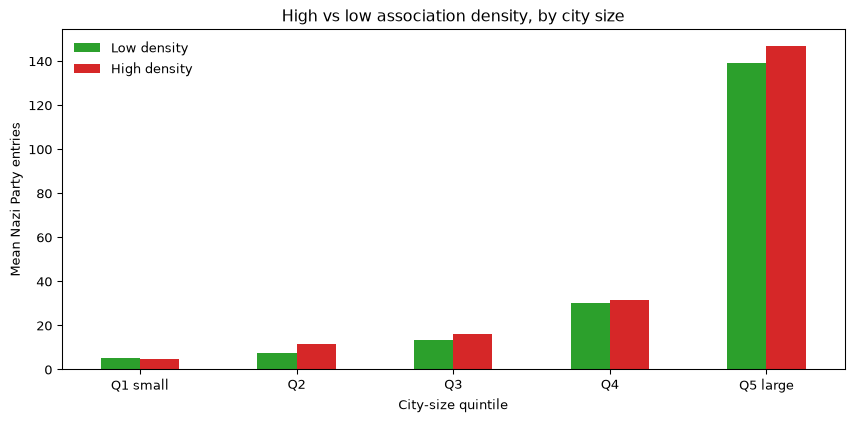

In [8]:
bowling["high_clubs"] = (bowling["clubs_all_pc"] >
                         bowling["clubs_all_pc"].median()).astype(int)
bowling["pop_quintile"] = pd.qcut(
    bowling["lnpop"], 5, labels=["Q1 small", "Q2", "Q3", "Q4", "Q5 large"]
)
means = (
    bowling.groupby(["pop_quintile", "high_clubs"], observed=True)["NSentry_total"]
    .mean()
    .unstack()
)
print(means.round(1).to_markdown())

fig, ax = plt.subplots(figsize=(9, 4.5))
means.plot(kind="bar", ax=ax, color=["C2", "C3"])
ax.set_xlabel("City-size quintile")
ax.set_ylabel("Mean Nazi Party entries")
ax.set_title("High vs low association density, by city size")
ax.legend(["Low density", "High density"], frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Bowling for Fascism: What the Reversal Teaches

- The count outcome reverses from about $-16.4$ to $+7.0$ once log
  population is included.
- Association density is much higher in small towns, and small towns
  have far fewer total entries; the bivariate result is driven by city
  size, not by a negative effect of associations.
- In four of the five city-size quintiles, high-density towns have more
  Nazi entries.
- This is a **real sign reversal**, but it is an omitted-variable/scale
  reversal, not the best-linear-approximation pathology on the [Caution
  slide](regression.qmd#caution) of `regression.qmd`. The synthetic
  Caution example remains the clean illustration of that distinct
  phenomenon.
- Lesson: match the outcome units to the estimand. Regressing a total on
  a per-capita treatment without controlling for population produces a
  misleading sign.
- This is the omitted-variable formula from the [Omitted Variables
  slide](regression.qmd#omitted-variables): population is the omitted
  $w$, and it is strongly negatively correlated with clubs per capita.
- The paper’s conclusion, using the per-capita outcome, is that denser
  social networks were associated with *faster* Nazi Party entry.

# Data Appendix

## Reproducing the Extracts

In [9]:
sources = pd.DataFrame([
    {
        "Dataset": "Nunn--Wantchekon",
        "Local file": "data/replication/Nunn_Wantchekon_AER_2011.dta",
        "Original source": "https://doi.org/10.3886/E112479V1",
        "Redistributed": "No",
    },
    {
        "Dataset": "OHIE",
        "Local file": "data/replication/ohie_analysis.csv",
        "Original source": "https://doi.org/10.7910/DVN/SJG1ED",
        "Redistributed": "Yes (processed extract; CC0 + terms)",
    },
    {
        "Dataset": "Project STAR",
        "Local file": "data/replication/star_k.csv",
        "Original source": "https://doi.org/10.7910/DVN/SIWH9F",
        "Redistributed": "Yes (processed extract; CC0)",
    },
    {
        "Dataset": "Bowling for Fascism",
        "Local file": "data/replication/bowling_cities.csv",
        "Original source": "https://doi.org/10.7910/DVN/EE6I7N",
        "Redistributed": "Yes (processed extract; CC0)",
    },
])
print(sources.to_markdown(index=False))

| Dataset             | Local file                                    | Original source                    | Redistributed                        |
|:--------------------|:----------------------------------------------|:-----------------------------------|:-------------------------------------|
| Nunn--Wantchekon    | data/replication/Nunn_Wantchekon_AER_2011.dta | https://doi.org/10.3886/E112479V1  | No                                   |
| OHIE                | data/replication/ohie_analysis.csv            | https://doi.org/10.7910/DVN/SJG1ED | Yes (processed extract; CC0 + terms) |
| Project STAR        | data/replication/star_k.csv                   | https://doi.org/10.7910/DVN/SIWH9F | Yes (processed extract; CC0)         |
| Bowling for Fascism | data/replication/bowling_cities.csv           | https://doi.org/10.7910/DVN/EE6I7N | Yes (processed extract; CC0)         |

## Data Notes

- **Nunn–Wantchekon:** the raw file is not redistributed. The code
  downloads the public IQSS mirror; the authoritative replication
  package is Nunn and Wantchekon (2011a) at openICPSR. If you need to
  download it manually, use the DOI and place the file at
  `data/replication/Nunn_Wantchekon_AER_2011.dta`.
- **OHIE:** the processed extract keeps only analysis variables and
  drops direct identifiers. The original is CC0 with additional terms:
  no commercial use, no re-identification, and citation of Finkelstein
  and Baicker (2012). Terms checked against the Dataverse record on
  2026-11-03; see the record for the full terms. To obtain the raw
  public-use zip, download it from the Dataverse record (accepting the
  guestbook) or from NBER (login may be required).
- **Project STAR:** CC0. The processed extract is `star_k.csv`; the
  original deposit is Achilles et al. (2008).
- **Bowling for Fascism:** CC0. The processed extract is
  `bowling_cities.csv`; the original deposit is Satyanath et al.
  (2017b).
- The script `data/replication/prepare_data.py` rebuilds the three
  processed extracts from the raw files. See
  `data/replication/README.md` for the download steps.

## Source Citations

- Nunn and Wantchekon (2011b); replication package: Nunn and Wantchekon
  (2011a).
- Finkelstein et al. (2012); data: Finkelstein and Baicker (2012).
- Krueger (1999); data: Achilles et al. (2008).
- Satyanath et al. (2017a); data: Satyanath et al. (2017b).

# References

Achilles, C. M., H. P. Bain, F. Bellott, et al. 2008. *Tennessee’s
Student Teacher Achievement Ratio (STAR) Project*. Harvard Dataverse.
<https://doi.org/10.7910/DVN/SIWH9F>.

Finkelstein, Amy, and Katherine Baicker. 2012. *Oregon Health Insurance
Experiment: Public Use Data*. Harvard Dataverse.
<https://doi.org/10.7910/DVN/SJG1ED>.

Finkelstein, Amy, Sarah Taubman, Bill Wright, et al. 2012. “The Oregon
Health Insurance Experiment: Evidence from the First Year.” *Quarterly
Journal of Economics* 127 (3): 1057–106.
<https://doi.org/10.1093/qje/qjs020>.

Krueger, Alan B. 1999. “Experimental Estimates of Education Production
Functions.” *Quarterly Journal of Economics* 114 (2): 497–532.
<https://doi.org/10.1162/003355399556052>.

Nunn, Nathan, and Leonard Wantchekon. 2011a. *Replication Data for: The
Slave Trade and the Origins of Mistrust in Africa*. AEA Data and Code
Repository, openICPSR. <https://doi.org/10.3886/E112479V1>.

Nunn, Nathan, and Leonard Wantchekon. 2011b. “The Slave Trade and the
Origins of Mistrust in Africa.” *American Economic Review* 101 (7):
3221–52. <https://doi.org/10.1257/aer.101.7.3221>.

Satyanath, Shanker, Nico Voigtländer, and Hans-Joachim Voth. 2017a.
“Bowling for Fascism: Social Capital and the Rise of the Nazi Party.”
*Journal of Political Economy* 125 (2): 478–526.
<https://doi.org/10.1086/690949>.

Satyanath, Shanker, Nico Voigtländer, and Hans-Joachim Voth. 2017b.
*Code and Data for: Bowling for Fascism: Social Capital and the Rise of
the Nazi Party*. Harvard Dataverse.
<https://doi.org/10.7910/DVN/EE6I7N>.

Schneider, Eric B. 2020. “Collider Bias in Economic History Research.”
*Explorations in Economic History* 78: 101356.
<https://doi.org/10.1016/j.eeh.2020.101356>.